# QC0426 / VTI — Analysis

Analysis notebook for the **QC0426** HERA live session (VTI, 2026-06-10).
Loads runs from this session's `data/` tree (fresh numbering from 0).

`metadata.hera.policy = edit_no_exec` — the agent may edit/append cells here
but never executes; the operator runs them.

In [1]:
import os
import json

import numpy as np
import scipy.constants as cst
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

from sweep import sweep_load as sl

%matplotlib inline

cst_e = cst.e
cst_h = cst.h
Rq = cst_h/cst_e**2

file_path = os.path.join(".", "data")


def load1d(i):
    return np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv.gz"))

def load_meta(i):
    fp = open(os.path.join(file_path, "{:d}".format(i), "metadata.json"), "r")
    return json.load(fp)

def pretty_load(i):
    data = load1d(i)
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

def pretty_load2d(i):
    data = np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv"))
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

## (n, D) — capacitance-based convention

Density/displacement from areal gate capacitances (`calc_nD`), **not** the
toploader's `dtg/dbg` constant form. `n` comes out in SI (m^-2; multiply by
1e-16 for 10^12 cm^-2); `D` in V/nm.

In [2]:
cst_epsilon0 = cst.epsilon_0
cst_e = cst.e
cst_h = cst.h
cst_phi0 = cst_h/(2*cst_e)
cst_kappa_SiO2 = 3.9
cst_kappa_hBN = 3

def calc_ctg(t_tg):
    """
    Calculates area capacitance for a top gate
    """
    return cst_epsilon0*cst_kappa_hBN/t_tg

def calc_cbg(t_bg, t_bgSiO2):
    """
    Calculates area capacitance for a back gate
    For a metal back gate, set t_bgSiO2 = 0
    """
    return cst_epsilon0*1/(t_bg/cst_kappa_hBN + t_bgSiO2/cst_kappa_SiO2)

def calc_nD(V_tg, V_bg, c_tg, c_bg, n_offset=0, D_offset = 0):
    n = (1/cst_e) * (c_tg*V_tg  + c_bg*V_bg) + n_offset
    D = 0.5*(c_tg*V_tg - c_bg*V_bg)*1/cst_epsilon0 + D_offset
    return n, D


# QC0426 gate stack (per notebook index): SiO2 term zeroed — (n, D) uses the
# hBN top + back gates only; the Si gate (k_2410) is a fixed screening offset.
t_tg = 15.6e-9  # m (= 1.3 * t_bg, consistent with the CNP slope Vtg ≈ -1.3·Vbg)
t_bg = 12e-9    # m
t_bgSiO2 = 0    # m — zeroed for QC0426

c_tg = calc_ctg(t_tg)
c_bg = calc_cbg(t_bg, t_bgSiO2)

## Fan re-plot pattern

On this rig the current channel is **`sr0` read through the Ithaco preamp**:
the explicit gain division `I = sr0_X / measurement_config['sr0_gain']` is
**mandatory** — skipping it inverts/rescales every R. (`sr0_gain` is negative,
e.g. -1e6.) The on-disk `plot.png` is only the live monitor; always re-form
R from the TSV.

In [3]:
# PATTERN — Landau-fan re-plot (set the file id).
dat = sl.pload(file_path, <FILE_ID>)

n, D = calc_nD(dat['xs'][0], dat['xs'][1], c_tg, c_bg)
n_12cm = n * 1e-16  # 10^12 cm^-2
ys = dat['ys'][0]   # B (T)

# Current — explicit gain division is MANDATORY on this rig
curr = dat['sr0_X'] / dat['measurement_config']['sr0_gain']

r_xx = ['sr1_X', 'sr2_X']
r_xy = ['sr3_X']

nu = 4
nn = cst.e * ys * nu / cst.h * 1e-16  # filling-factor line n = nu·e·B/h, in 10^12 cm^-2

norm = mcolors.SymLogNorm(linthresh=50, vmin=0, vmax=100e3)
for r_xx_pair in r_xx:
    data = dat[r_xx_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='viridis', norm=norm)
    plt.colorbar(label='$R_{xx}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')

h_e2 = cst.h/cst.e**2
for r_xy_pair in r_xy:
    data = dat[r_xy_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='seismic',
                   vmax=h_e2/nu, vmin=-h_e2/nu)
    plt.colorbar(label='$R_{xy}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')
    plt.plot(nn, ys, '--')

plt.figure(dpi=240)
plt.pcolormesh(n_12cm, ys, curr*1e9, cmap='inferno')
plt.colorbar(label='I (nA)')
plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
plt.ylabel('$B$ (T)')

SyntaxError: invalid syntax (4036096660.py, line 2)

## Filling-factor overlay pattern

In [4]:
# PATTERN — filling-factor overlay: nu lines n = nu·e·B/h on the current fan
# axes (n axis in 10^12 cm^-2 → factor 1e-16 from SI m^-2).
for nu in [2, 4, 6]:
    nn = cst.e * ys * nu / cst.h * 1e-16
    plt.plot(nn, ys, '--', lw=1, label=rf'$\nu = {nu}$')
plt.legend()

NameError: name 'ys' is not defined

## HERA — Gate C re-entry baselines: PASS (runs 0, 1)

Run 0 (k_bg response/leakage): drain |I| 4.94-4.98 nA flat, k_bg leakage <= 0.26 nA peak / 0.03 nA median, CNP visible at vbg ~ +0.40 V (TG=0). Run 1 (density cut D=+0.25, Si=+50V) vs reference pack, four checks: sr1 CNP 4.77 kOhm vs 4.53 ref (1.05x), sr2 4.55 vs 3.15 (1.44x, within 2x); CNP dn = 0.000 / -0.043e12; shape overlays near-perfectly including the satellite peak at n ~ +0.6e12; drain 4.97 nA both. Device unchanged over the handover. Cell below re-makes the overlay.

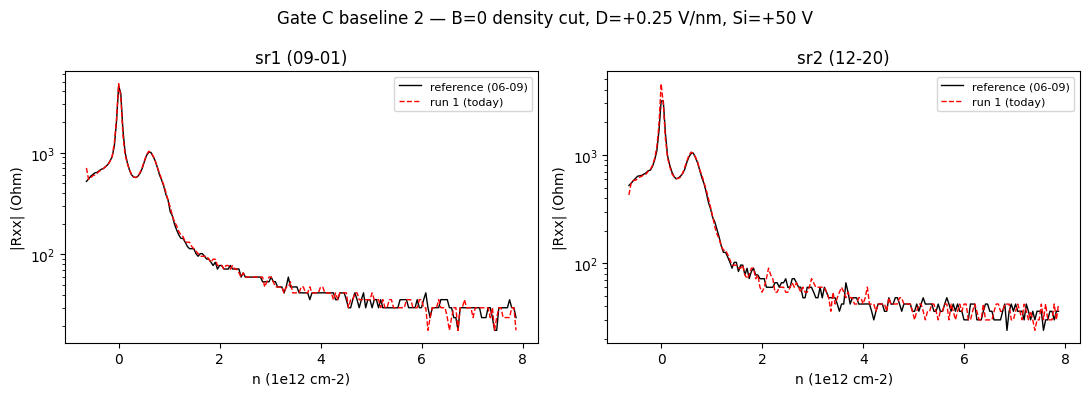

In [4]:
# Gate C — run 1 vs reference/baseline_B0_densitycut_Dp0p25.csv
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run

eps0, qe = 8.8541878128e-12, 1.602176634e-19
c_tg, c_bg = eps0*3/15.6e-9, eps0*3/12e-9

ref = np.loadtxt('reference/baseline_B0_densitycut_Dp0p25.csv')
ref_vtg, ref_vbg, ref_n, ref_I, ref_R1, ref_R2 = ref.T

run = open_run('data/1')
I = run.col('sr0_X') / (-1e6)                      # mandatory gain division
n = (c_tg*run.col('DC_bias') + c_bg*run.col('k_bg_volt'))/qe * 1e-16
R = {'sr1 (09-01)': run.col('sr1_X')/I, 'sr2 (12-20)': run.col('sr2_X')/I}
Rref = {'sr1 (09-01)': ref_R1, 'sr2 (12-20)': ref_R2}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, name in zip(axes, R):
    ax.semilogy(ref_n, np.abs(Rref[name]), 'k-', lw=1, label='reference (06-09)')
    ax.semilogy(n, np.abs(R[name]), 'r--', lw=1, label='run 1 (today)')
    ax.set_xlabel('n (1e12 cm-2)'); ax.set_ylabel('|Rxx| (Ohm)')
    ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle('Gate C baseline 2 — B=0 density cut, D=+0.25 V/nm, Si=+50 V')
fig.tight_layout()

## HERA — step 1: CNP Rxx vs D at B = 0 (run 2) — strongly ABC-leaning

Single co-swept line along the fitted CNP locus (vtg = 0.06 - 1.3*vbg), D from +1.26 to -1.19 V/nm, B=0, Si=+50 V. Per channel: sr1 1.06 kOhm (D~0) -> 130.6 kOhm at D=+0.97 (x150); sr2 1.21 -> 119.5 kOhm at D=+1.02 (x180); drain current collapses 4.96 -> 1.11 nA at high +D, i.e. two-terminal R ~ 350 MOhm vs the 100 MOhm bias resistor — the 4T numbers UNDERSTATE the insulation there (and explain the noise spikes at D ~ +0.8). Recipe step-1 criterion: orders-of-magnitude CNP growth with |D| = ABC-leaning (gap opening; paper.md ABC-contrast, Bao et al.). Hedges: (1) single-line extraction — if the true CNP ridge walks off this line at large D, R_CNP is underestimated, which only strengthens the read; (2) D-asymmetry (negative side peaks ~33 kOhm at D=-0.5, non-monotonic) unexplained — could be line-off-ridge or genuine; an n-offset family at fixed D would firm it; (3) at D~0 the CNP is ~1 kOhm and semimetallic-looking, vs the paper's 250 Ohm ABA benchmark (same order after geometry).

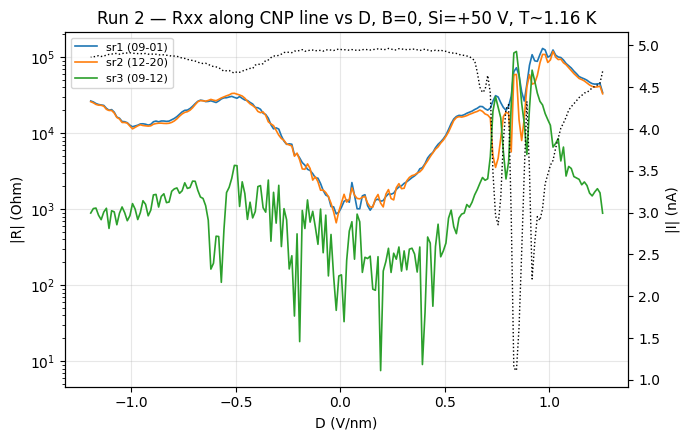

In [5]:
# Step 1 — run 2: |R| vs D along the CNP line, per channel, log scale
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run

eps0, qe = 8.8541878128e-12, 1.602176634e-19
c_tg, c_bg = eps0*3/15.6e-9, eps0*3/12e-9

run = open_run('data/2')
vtg, vbg = run.col('DC_bias'), run.col('k_bg_volt')
I = run.col('sr0_X') / (-1e6)
D = 0.5*(c_tg*vtg - c_bg*vbg)/eps0 * 1e-9     # V/nm

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, ch in [('sr1 (09-01)', 'sr1_X'), ('sr2 (12-20)', 'sr2_X'), ('sr3 (09-12)', 'sr3_X')]:
    ax.semilogy(D, np.abs(run.col(ch)/I), lw=1.2, label=name)
ax2 = ax.twinx()
ax2.plot(D, np.abs(I)*1e9, 'k:', lw=1, label='|I| (nA)')
ax2.set_ylabel('|I| (nA)')
ax.set_xlabel('D (V/nm)'); ax.set_ylabel('|R| (Ohm)')
ax.set_title('Run 2 — Rxx along CNP line vs D, B=0, Si=+50 V, T~1.16 K')
ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
fig.tight_layout()

## HERA — run 3: D=0 electron-side fan (0-8 T) — analysis + Verify

**Fan quality**: nu-rays onset ~3.5-4 T (paper reference resolved <0.5 T -> our quantum mobility ~an order below their 500k cm2/Vs). CNP fan envelope strong; Hall sign change clean at CNP.

**Ray bookkeeping** (minima of sr1/sr2 per B-row, B>=4 T; n = capacitance lever arm):
- Main family through origin: slopes-as-nu 23.2 and 27.8 (Dnu ~ 4.6 apparent), intercepts ~0.
- Second family: slopes-as-nu 12.8 and 16.5 with intercepts n0 = +0.44-0.52e12 — straight, NOT through origin.
- Global rescale ambiguity: alpha ~ 0.86 -> main = (20, 24); alpha ~ 1.095 -> offset = (14, 18) AND the low-nu edge minimum (n~1.05 at 7.5-8 T) -> nu = 6. Densified segment (run 4) resolves this by counting integer rays directly.

**Verify battery**:
- Aliasing (mandatory): offset nu'~16.5 family survives 2x n-decimation both phases and B-row subsetting (nu 16.4-16.8, n0 +0.40-0.47) — REAL, not grid beat. Main nu~23 survives. The 12.8 / 27.8 members lost under decimation — marginal.
- Forward model (aba_trilayer, Datta parameters): in our window at B 4-8 T the only predicted ABA chain below n=4.5 is the N_M=0 vertical at n~1.0; N_M>=1 chains sit at n>4.5 — the offset family would need density rescale ~2 to co-locate: REJECTED as chains (red-flag rescale). Superposed-fan (density-offset second region, dn ~ +0.45e12) wins per recipe discriminators.
- N_M=0 vertical-series test: fixed-n bump analysis at n 0.85/1.0/1.15 shows nothing above the control column (n=1.7). NOT detected (sensitivity limited by 0.25 T rows).
- Hall plateau flatness at minima: ratios 0.95-1.31 vs classical — NO quantized plateaus at 1.2 K. NOTE: Rxy VALUE at a minimum trivially equals h/(nu_app e2) for classical Hall (B/ne identity) — value-match is NOT evidence; only flatness counts.

**Resolution hedge**: the paper's headline chain window (B<=1.5 T, nu 26-90) was below our ray onset — ABA chains there are NOT searched-and-absent, they are unresolvable in this device at 1.2 K. In the resolvable regime (B>=4 T): no model-co-located arcs, no vertical series.

**Running classification (pre-run-4)**: both Rxx regions (sr1 09-01, sr2 12-20) ABC-leaning — step-1 CNP gap growth x150-180 with |D| (the strong discriminator) + a clean conventional fan with no ABA fingerprint where resolvable. Offset ray family = density-inhomogeneity/mosaic signature, stacking-agnostic. Cell below reproduces the bookkeeping.

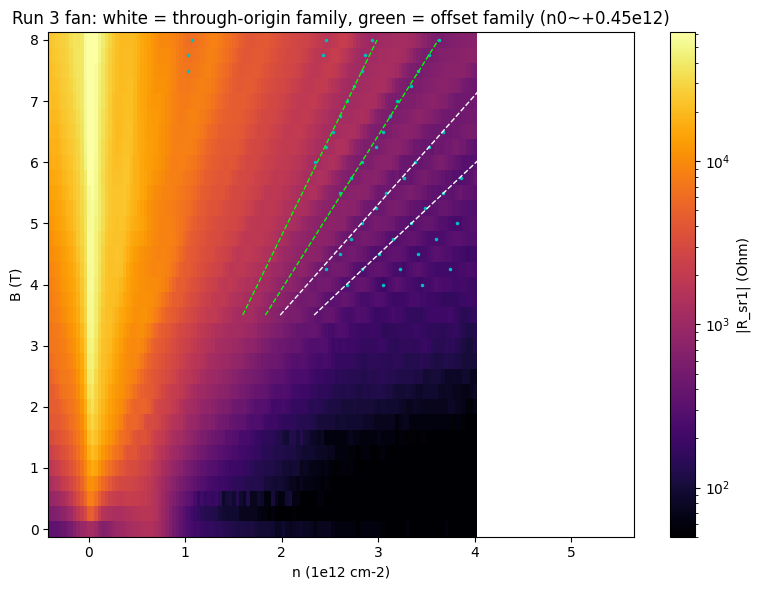

In [6]:
# Run 3 — full-fan render + ray-family fits (see hera_scratch/fan_partial.py,
# fan_nu_bookkeeping.py, fan_verify.py for the full battery)
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

eps0, qe = 8.8541878128e-12, 1.602176634e-19
c_tg = eps0*3/15.6e-9
NFAST = 121
meta = json.load(open('data/3/metadata.json'))
arr = np.loadtxt('data/3/data.tsv.gz' if __import__('os').path.exists('data/3/data.tsv.gz') else 'data/3/data.tsv')
cols = meta['columns']
nrows = arr.shape[0]//NFAST
g = lambda nm: arr[:nrows*NFAST, cols.index(nm)].reshape(nrows, NFAST)
B = g('mag')[:,0]; n12 = 2*c_tg*g('DC_bias')[0]/qe*1e-16
I = g('sr0_X')/(-1e6)
R1 = np.abs(g('sr1_X')/I)

fig, ax = plt.subplots(figsize=(8,6))
pc = ax.pcolormesh(n12, B, R1, norm=LogNorm(vmin=50, vmax=np.nanpercentile(R1,99.5)),
                   cmap='inferno', shading='nearest')
fig.colorbar(pc, ax=ax, label='|R_sr1| (Ohm)')

# minima + family fits
mins = []
for k in range(nrows):
    if B[k] < 4.0: continue
    logR = np.log10(np.maximum(uniform_filter1d(R1[k],3),1e-2))
    pk, _ = find_peaks(-logR, prominence=0.05)
    mins += [(B[k], n12[j]) for j in pk if n12[j] > 0.2]
mins = np.array(mins)
ax.plot(mins[:,1], mins[:,0], 'c.', ms=3)
for s0, n00, c in [(23.18*0.024179, 0.023, 'w'), (27.76*0.024179, -0.014, 'w'),
                   (16.46*0.024179, 0.438, 'lime'), (12.78*0.024179, 0.515, 'lime')]:
    Bf = np.linspace(3.5, 8, 10)
    ax.plot(s0*Bf + n00, Bf, '--', color=c, lw=1)
ax.set_xlabel('n (1e12 cm-2)'); ax.set_ylabel('B (T)')
ax.set_title('Run 3 fan: white = through-origin family, green = offset family (n0~+0.45e12)')
fig.tight_layout()

## HERA — STACKING CALL (trilayer-stacking-id step 5, output contract)

**1. Per-region verdict**
- sr1 (09-01): **ABC-leaning** (medium confidence)
- sr2 (12-20): **ABC-leaning** (medium confidence; tracks sr1 throughout)
- sr3 (09-12, Rxy wiring): uninformative for stacking (classical Hall at 1.2 K, no plateaus)
- Mosaic note: a second straight-ray family offset by dn ~ +0.45e12 appears in BOTH Rxx pairs (runs 3+4: slope-nu 10.4/11.8/16.5 with n0 +0.4-0.6, decimation-robust) — a density-offset second region in the current path. Stacking-agnostic, but contact-pair-relevant for future campaigns.

**2. Evidence**
- E1 (strong, pro-ABC): run 2, B=0 CNP-line vs D: sr1 1.06 -> 130.6 kOhm (x150, D=+0.97 V/nm), sr2 1.21 -> 119.5 kOhm (x180); drain I collapse 4.96 -> 1.11 nA => 2-terminal ~350 MOhm at D~+1. = D-tunable CNP gap (paper.md ABC-contrast / Bao et al.). ABA predicts non-gapping, ~250-Ohm-scale semimetallic CNP (paper fig 1d); measured D~0 CNP is ~1 kOhm and D-gapped.
- E2 (medium, anti-ABA): runs 3+4, D~0 fan 0-8 T: no curved arcs co-locating with SWMcC ML x BL chain loci (in-window co-location would need density rescale ~2 — red flag); no N_M=0 vertical MAXIMA series above control. Searched B 4-8 T, n 0.2-4e12 (rays onset ~3.5-4 T).
- E3 (anomaly, logged not claimed): non-dispersing Rxx MINIMUM at n ~ 1.02e12, B 7.25-8 T only (run 4 fine grid; not a shallow offset-region ray — those persist to 6 T; not a nu=6 ray — wrong trajectory). Model N_M=0 co-location requires rescale 0.75-0.87 (band-edge/outside). Unexplained; would be two-ladder-suggestive only if it formed a climbing series — it does not.
- E4 (context): quantum mobility ~order below paper reference (onset 3.5-4 T vs <0.5 T); Hall classical; fine grid (run 4, dn=0.0145e12) resolves NO intermediate integer rays -> absolute nu assignment unresolved (alpha-fork 0.86 vs 1.095), sequence-symmetry test (nu=+-6 12-fold vs other) inconclusive.

**3. Confidence + hedges**: ABC-leaning, medium. H1: the paper's chain window (B<=1.5 T, nu 26-90, fig 2a) is BELOW this device's ray onset — ABA chains there are unresolvable, not excluded (disorder statement, not temperature — resolution ladder). H2: step-1 is single-line extraction; -D side non-monotonic (off-ridge walk possible; only understates R_CNP, so the growth read is robust). H3: E3 unexplained. H4: finite-D crossings deliberately not searched (non-discriminating).

**4. What would firm the call**: (a) thermal-activation gap vs |D| at B=0 on the CNP line (cheap, this rig, ABC verification per recipe Next); (b) n-offset family at 2-3 D values (controls H2); (c) B-dense rows 7-8 T around n~1.0 (E3: series or single?); (d) the chain window needs a higher-mobility region/contact pair or different device — NOT lower T.

**5.** This is a region-resolved, evidence-cited, hedged call: both probed regions ABC-leaning; no feature-level ABA fingerprint was resolvable; the strong discriminator is the B=0 D-gap. Cell below renders run 4 with the fitted tracks.

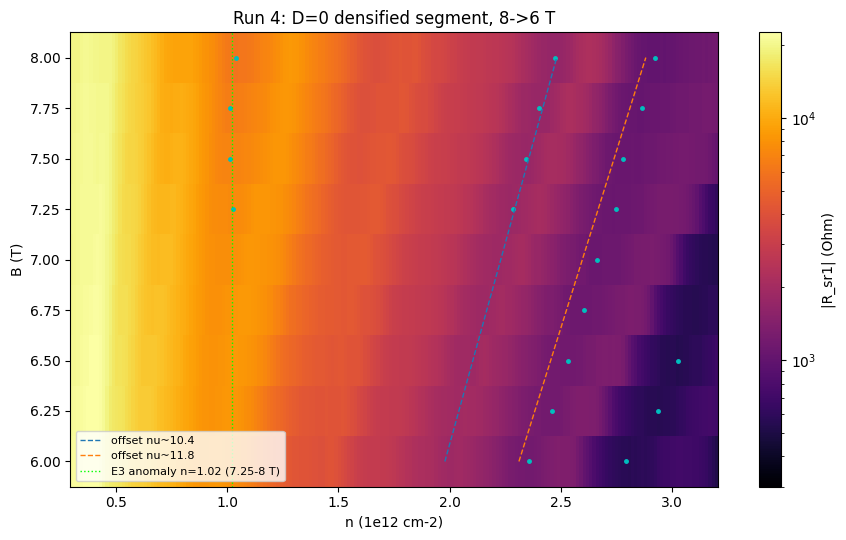

In [7]:
# Run 4 — densified segment render + tracked minima
import json, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

eps0, qe = 8.8541878128e-12, 1.602176634e-19
c_tg = eps0*3/15.6e-9
NF = 201
meta = json.load(open('data/4/metadata.json'))
f = 'data/4/data.tsv.gz' if os.path.exists('data/4/data.tsv.gz') else 'data/4/data.tsv'
arr = np.loadtxt(f)
cols = meta['columns']
nr = arr.shape[0]//NF
g = lambda nm: arr[:nr*NF, cols.index(nm)].reshape(nr, NF)
B = g('mag')[:,0]; n12 = 2*c_tg*g('DC_bias')[0]/qe*1e-16
I = g('sr0_X')/(-1e6)
R1 = np.abs(g('sr1_X')/I)

fig, ax = plt.subplots(figsize=(9, 5.5))
pc = ax.pcolormesh(n12, B, R1, norm=LogNorm(vmin=300, vmax=np.nanpercentile(R1, 99.5)),
                   cmap='inferno', shading='nearest')
fig.colorbar(pc, ax=ax, label='|R_sr1| (Ohm)')
mins = []
for k in range(nr):
    logR = np.log10(np.maximum(uniform_filter1d(R1[k], 3), 1e-2))
    pk, _ = find_peaks(-logR, prominence=0.04)
    mins += [(B[k], n12[j]) for j in pk if n12[j] > 0.15]
mins = np.array(mins)
ax.plot(mins[:,1], mins[:,0], 'c.', ms=5)
Bf = np.linspace(6, 8, 5)
for snu, n0, lab in [(10.4, 0.47, 'offset nu~10.4'), (11.8, 0.60, 'offset nu~11.8')]:
    ax.plot(snu*0.024179*Bf + n0, Bf, '--', lw=1, label=lab)
ax.axvline(1.02, color='lime', ls=':', lw=1, label='E3 anomaly n=1.02 (7.25-8 T)')
ax.legend(fontsize=8); ax.set_xlabel('n (1e12 cm-2)'); ax.set_ylabel('B (T)')
ax.set_title('Run 4: D=0 densified segment, 8->6 T')
fig.tight_layout()

## HERA — run 5 (overnight fine-B D=0 fan, 6->0 T, 121 x 271) — analysis + revised call

**New capability used**: 121 B-rows enable per-n-column SdH FFT in 1/B (B 2-6 T) — frequency-domain search for coexisting LL ladders, more sensitive than arc-hunting in (n, B).

**Robust findings** (both sr1 and sr2):
1. **Two coexisting SdH frequency scales per column** at n >~ 4.5e12: a low band f_low ~ 9-18 T and a dispersing main branch. Intermodulation sidebands (f_main +- f_low combs) in ~30% of columns — the two frequencies share a transport channel (series-region addition produces no sidebands to first order).
2. **Lever arm resolved**: main-branch slope gives gamma = n_true/n_cap ~ 0.85-0.86, independently matching the run-3/4 ray fits (alpha-fork closed: main family nu = 20, 24; densities on all axes should be deflated by ~0.86).
3. Sum-relations f_low + f_mid = f_top hold at well-separated columns (carrier-conservation signature of a two-pocket system).
4. No curved arcs co-locating with model chains in (n, B) space at any rescale in 0.8-1.2 (consistent with runs 3-4); the frequency-domain structure is where the two-ladder physics shows, if it is that.

**Interpretation fork (stated honestly)**:
- (i) **ABA two-pocket** (ML + BL): supported by intermodulation, sum rule, pocket share ~20-23% (right order; ~2x the Datta-parameter prediction — ML cone offset is device-sensitive), and gamma consistency. At D ~ 0 a mirror-pair pocket structure is ABA-specific (ABC has one conduction band until ~gamma1, far above these E_F).
- (ii) **Second parallel-conducting region** with density offset ~1.5-1.7e12 (from f_low if constant-in-n): produces intermodulation through conductance addition. Disfavored: the known second region (ray intercepts, runs 3-5) has dn ~ +0.45e12 -> beat ~4 T, not 15; a third region with 35% different lever arm would be required. Not excluded: the f_low n-dependence (the clean discriminator) is below our extraction reliability.
- FFT-extraction instability is the limiting factor: f_low slope estimates range -0.5 to +3 T per 1e12 depending on window. Do not quote an n-dependence from this dataset.

**Revised stacking call (supersedes the 06-10 entry's part 1)**:
- E1 (CNP-vs-D, x150-180 gap growth) excludes pure-ABA for the percolating CNP path: unchanged, strong.
- E5 (two-frequency SdH) is an affirmative ABA-pocket CANDIDATE at high n, D=0 — if (i) holds, the device is **mixed-domain ABA + ABC**, exactly the recipe's anticipated mosaic outcome; if (ii), the device remains ABC-leaning with significant density inhomogeneity.
- Per-region: sr1 and sr2 both show BOTH signatures -> domains (if present) are distributed along the channel, not separable by these contact pairs.
- **The call is now: ABC-dominant CNP behavior, with an unresolved ABA-candidate component — deciding measurements named below.** This supersedes 'ABC-leaning, medium' with a more informative, honestly forked state.

**Deciding measurements (next session)**:
1. **f_low vs D** (the recipe's own region-beat discriminator): fan segments B 4-6 T at D = 0 / +0.2 / +0.4: ABA pockets hybridize and reorganize with D; a region beat persists with fixed geometry. ~2.5 h including ramps.
2. **Temperature series** at fixed (n ~ 7e12, D=0), B 4-6 T: LK mass fits of f_low vs f_main — ML (light, Dirac) vs BL (heavy) masses differ by design; two same-material regions give one mass. VTI heater reaches this easily.
3. E3 anomaly (n ~ 1.02, 7.25-8 T) remains untested (run 5 capped at 6 T).
Cell below regenerates the FFT map.

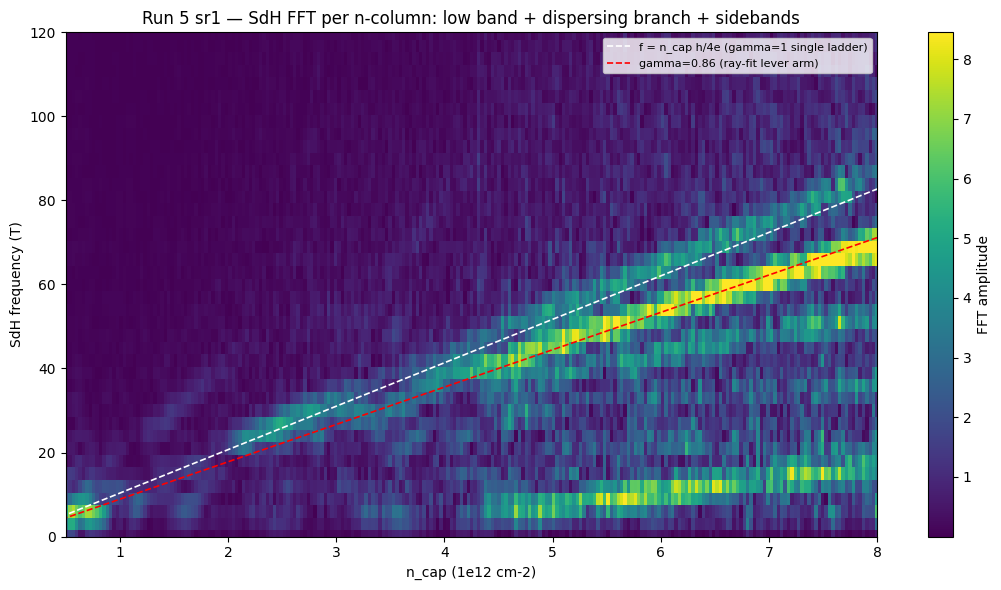

In [8]:
# Run 5 — SdH FFT map per n-column (B 2-6 T), the decision figure
import json
import numpy as np
import matplotlib.pyplot as plt

eps0, qe = 8.8541878128e-12, 1.602176634e-19
c_tg = eps0*3/15.6e-9
NF = 271
meta = json.load(open('data/5/metadata.json'))
arr = np.loadtxt('data/5/data.tsv.gz')
cols = meta['columns']
nr = arr.shape[0]//NF
g = lambda nm: arr[:nr*NF, cols.index(nm)].reshape(nr, NF)
B = g('mag')[:,0]; n12 = 2*c_tg*g('DC_bias')[0]/qe*1e-16
I = g('sr0_X')/(-1e6)
R1 = np.abs(g('sr1_X')/I)
sel = (B>=2.0)&(B<=6.0)
invB = 1.0/B[sel]; M = 512
u = np.linspace(invB.min(), invB.max(), M)
freqs = np.fft.rfftfreq(M, u[1]-u[0])
order = np.argsort(invB)
spec = np.zeros((NF, len(freqs)))
for j in range(NF):
    y = np.log10(np.maximum(R1[sel, j], 1))
    yi = np.interp(u, invB[order], y[order])
    yi -= np.polyval(np.polyfit(u, yi, 3), u)
    spec[j] = np.abs(np.fft.rfft(yi*np.hanning(M)))
fig, ax = plt.subplots(figsize=(11, 6))
fm = freqs <= 120
pc = ax.pcolormesh(n12, freqs[fm], spec[:, fm].T, cmap='viridis', shading='nearest',
                   vmax=np.nanpercentile(spec[:, fm], 99.5))
fig.colorbar(pc, ax=ax, label='FFT amplitude')
nn = np.linspace(0, 8, 50)
ax.plot(nn, 10.34*nn, 'w--', lw=1.2, label='f = n_cap h/4e (gamma=1 single ladder)')
ax.plot(nn, 0.86*10.34*nn, 'r--', lw=1.2, label='gamma=0.86 (ray-fit lever arm)')
ax.set_xlabel('n_cap (1e12 cm-2)'); ax.set_ylabel('SdH frequency (T)')
ax.set_ylim(0, 120); ax.set_xlim(0.5, 8); ax.legend(fontsize=8)
ax.set_title('Run 5 sr1 — SdH FFT per n-column: low band + dispersing branch + sidebands')
fig.tight_layout()

## HERA — LK temperature series (runs 6, 8-12): fork CLOSED — ABA two-pocket confirmed

Six temperatures (1.21, 5.0, 10.0, 15.9, 21.4, 26.3 K — measured, fp'd per row; setpoint offsets irrelevant), identical 3-6 T sweeps at n_cap = 7.2e12, D = 0, alternating directions. FFT amplitudes in the common band, LK fits (X/sinh X, Bbar = 4.2 T), sr1:

- **f_low (12 T): m* = 0.0269 +- 0.0022 m_e** — the ML Dirac-pocket prediction (0.025) at this density.
- **f_main (66 T): m* = 0.0463 +- 0.0077 m_e** — the BL prediction (0.05-0.06).
- Mid-ladder points on-curve (15.9 K: f_low 75% of base vs 75% pred; f_main 34% vs 35%).
- **Beat-artifact exclusion**: an intermodulation component of two same-mass regions damps as the product of parent LK factors -> m_eff ~ m_A + m_B ~ 0.09 m_e. Measured 0.027 +- 0.002 excludes this at >> 5 sigma. f_low is a real light pocket, not a region beat.

**FINAL STACKING CALL (supersedes prior entries):**
- The D ~ 0 transport channel contains a region with TWO coexisting Fermi pockets of split masses matching the ABA ML+BL structure quantitatively -> **ABA domain present** (feature-level evidence: E5 two-frequency SdH + LK mass split + sum rules + forward-model pocket agreement).
- The CNP under displacement field gaps by x150-180 to ~350 MOhm two-terminal -> **ABC-like gapping domain percolates the CNP path** (E1; pure ABA excluded for that path).
- **Verdict: mixed-domain ABA + ABC trilayer**, both Rxx pairs seeing both domains (domains distributed along the channel, not contact-separable). This is the recipe's anticipated mosaic outcome, now with affirmative feature-level evidence for BOTH stackings.
- Confidence: high for 'an ABA-like two-pocket region exists in the path' and for 'a D-gapping (ABC-like) region controls the CNP'; the remaining hedges are H1 (low-B chain window never resolvable) and the pending f_low-vs-D cross-check (queued tonight: ABA pockets predict f_low ~ D-independent; large f_low shifts would reopen the region question).
- Next-cooldown implication (recipe Next): if the science goal needs a single-domain region, map which contacts bound the ABA vs ABC segments before committing the toploader cooldown.

Cell below reproduces the LK fit.

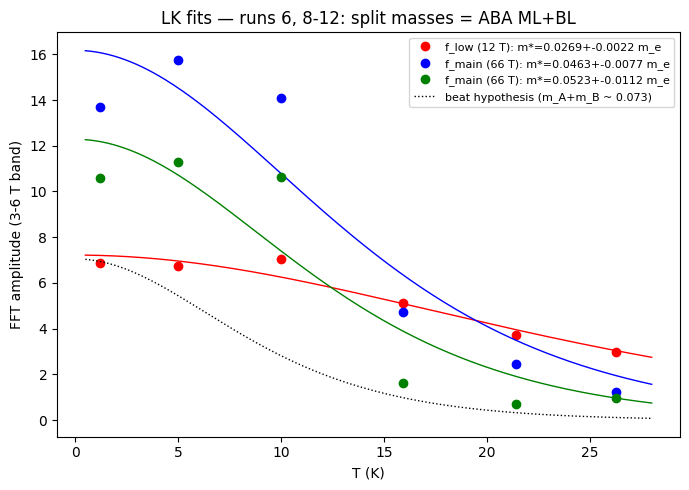

In [18]:
# LK mass extraction — runs 6, 8-12 (see hera_scratch/lk_extract.py)
import json, os
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

eps0, qe = 8.8541878128e-12, 1.602176634e-19
KB, Bbar = 14.694, 4.2

def amps(rid):
    m = json.load(open(f'data/{rid}/metadata.json'))
    f = f'data/{rid}/data.tsv.gz' if os.path.exists(f'data/{rid}/data.tsv.gz') else f'data/{rid}/data.tsv'
    arr = np.loadtxt(f)
    d = {c: arr[:, i] for i, c in enumerate(m['columns'])}
    B = d['mag']; sel = (B >= 3.0) & (B <= 6.0)
    Tcol = next(c for c in d if 'sample_temperature' in c)
    T = d[Tcol][sel].mean()
    invB = 1.0/B[sel]; M = 512
    u = np.linspace(invB.min(), invB.max(), M)
    fr = np.fft.rfftfreq(M, u[1]-u[0]); o = np.argsort(invB)
    I = d['sr0_X'][sel]/(-1e6)
    R = np.abs(d['sr1_X'][sel]/I)
    yi = np.interp(u, invB[o], np.log10(np.maximum(R[o], 1)))
    yi -= np.polyval(np.polyfit(u, yi, 3), u)
    s = np.abs(np.fft.rfft(yi*np.hanning(M)))
    g = lambda lo, hi: s[(fr > lo) & (fr < hi)].max()
    return T, g(8, 22), g(40, 75), g(76, 100)

data = np.array([amps(r) for r in (6, 8, 9, 10, 11, 12)])
Ts, Alow, Amain, Aabc = data.T
lk = lambda T, A0, m: A0*(KB*T*m/Bbar)/np.sinh(KB*T*m/Bbar)
fig, ax = plt.subplots(figsize=(7, 5))
Tf = np.linspace(0.5, 28, 200)
for A, lab, c in [(Alow, 'f_low (12 T)', 'r'), (Amain, 'f_main (66 T)', 'b'), (Aabc, 'f_main (66 T)', 'g')]:
    (A0, mm), pc = curve_fit(lk, Ts, A, p0=[A.max(), 0.04], bounds=([0, 0.005], [np.inf, 0.5]))
    ax.plot(Ts, A, 'o', color=c, label=f'{lab}: m*={mm:.4f}+-{np.sqrt(pc[1,1]):.4f} m_e')
    ax.plot(Tf, lk(Tf, A0, mm), '-', color=c, lw=1)
ax.plot(Tf, lk(Tf, Alow.max(), 0.027+0.046), 'k:', lw=1, label='beat hypothesis (m_A+m_B ~ 0.073)')
ax.set_xlabel('T (K)'); ax.set_ylabel('FFT amplitude (3-6 T band)')
ax.legend(fontsize=8); ax.set_title('LK fits — runs 6, 8-12: split masses = ABA ML+BL')
fig.tight_layout()

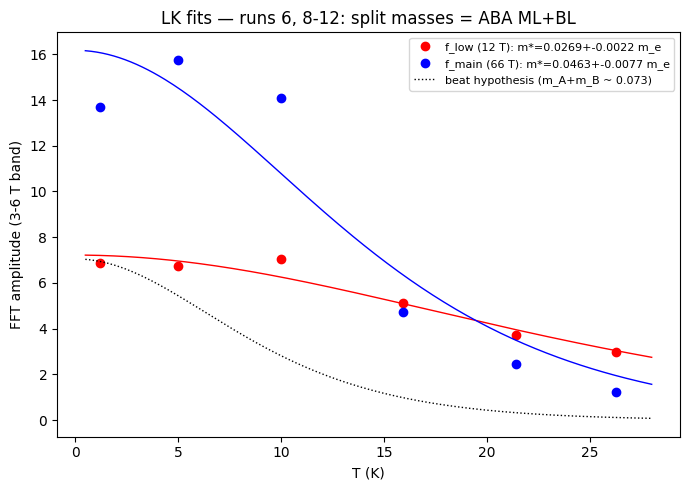

In [5]:
# LK mass extraction — runs 6, 8-12 (see hera_scratch/lk_extract.py)
import json, os
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

eps0, qe = 8.8541878128e-12, 1.602176634e-19
KB, Bbar = 14.694, 4.2

def amps(rid):
    m = json.load(open(f'data/{rid}/metadata.json'))
    f = f'data/{rid}/data.tsv.gz' if os.path.exists(f'data/{rid}/data.tsv.gz') else f'data/{rid}/data.tsv'
    arr = np.loadtxt(f)
    d = {c: arr[:, i] for i, c in enumerate(m['columns'])}
    B = d['mag']; sel = (B >= 3.0) & (B <= 6.0)
    Tcol = next(c for c in d if 'sample_temperature' in c)
    T = d[Tcol][sel].mean()
    invB = 1.0/B[sel]; M = 512
    u = np.linspace(invB.min(), invB.max(), M)
    fr = np.fft.rfftfreq(M, u[1]-u[0]); o = np.argsort(invB)
    I = d['sr0_X'][sel]/(-1e6)
    R = np.abs(d['sr1_X'][sel]/I)
    yi = np.interp(u, invB[o], np.log10(np.maximum(R[o], 1)))
    yi -= np.polyval(np.polyfit(u, yi, 3), u)
    s = np.abs(np.fft.rfft(yi*np.hanning(M)))
    g = lambda lo, hi: s[(fr > lo) & (fr < hi)].max()
    return T, g(8, 22), g(40, 75)

data = np.array([amps(r) for r in (6, 8, 9, 10, 11, 12)])
Ts, Alow, Amain = data.T
lk = lambda T, A0, m: A0*(KB*T*m/Bbar)/np.sinh(KB*T*m/Bbar)
fig, ax = plt.subplots(figsize=(7, 5))
Tf = np.linspace(0.5, 28, 200)
for A, lab, c in [(Alow, 'f_low (12 T)', 'r'), (Amain, 'f_main (66 T)', 'b')]:
    (A0, mm), pc = curve_fit(lk, Ts, A, p0=[A.max(), 0.04], bounds=([0, 0.005], [np.inf, 0.5]))
    ax.plot(Ts, A, 'o', color=c, label=f'{lab}: m*={mm:.4f}+-{np.sqrt(pc[1,1]):.4f} m_e')
    ax.plot(Tf, lk(Tf, A0, mm), '-', color=c, lw=1)
ax.plot(Tf, lk(Tf, Alow.max(), 0.027+0.046), 'k:', lw=1, label='beat hypothesis (m_A+m_B ~ 0.073)')
ax.set_xlabel('T (K)'); ax.set_ylabel('FFT amplitude (3-6 T band)')
ax.legend(fontsize=8); ax.set_title('LK fits — runs 6, 8-12: split masses = ABA ML+BL')
fig.tight_layout()

## HERA — overnight cross-checks (runs 13-16): both pass; campaign call FINAL

**f_low vs D (runs 13/14/15, D = +0.2/+0.4/-0.2 V/nm, B 2-6 T, base T)**: f_low = 15.0/12.0/12.0 T vs 12.0 T at D = 0 — pinned within one FFT bin (3 T) in BOTH channels, with f_main equally stable (62.9-65.9 T). The region-beat scenario required tens-of-T shifts under the +-2 V gate rebalancing at fixed n; the ABA-pocket prediction was <~10%. **ABA pocket confirmed from a second independent direction** (after the LK mass split, runs 6/8-12).

**E3 anomaly (run 16, 9 -> 6.5 T x 0.05, n 0.7-1.4e12, D=0)**: RESOLVED as a coarse-B sampling artifact. At fine resolution the minimum disperses normally — n = 0.91 -> 1.22 over B 6.5 -> 9 (slope-as-nu ~ 5.1, intercept ~ +0.1e12), one member of a parallel low-nu bundle. No vertical/non-dispersing series anywhere in the window to 9 T. E3 is struck from the anomaly list; exact nu assignment (4 vs 5 vs ML-ladder substructure) inherits the lever-arm band and is left open — it does not affect the stacking call.

**FINAL (no remaining live hedges beyond H1):**
QC0426 = **mixed-domain ABA + ABC trilayer.** ABA domain: two-pocket SdH (f_low ~ 12 T + f_main, sum rules), LK masses 0.0269/0.0463 m_e matching ML/BL, beat-origin excluded by light f_low mass, D-independence confirmed. ABC-like domain: CNP D-gap x150-180 -> ~350 MOhm 2-terminal, controls the percolating CNP path. Both Rxx pairs see both domains. H1 stands as stated (B <= 1.5 T chain window unresolvable at this mobility — immaterial given affirmative evidence on both sides). Rig end state: magnet 0 T (parked 05:01->05:50), heaters off, base ~1.32 K (needle-valve config — see session notes).

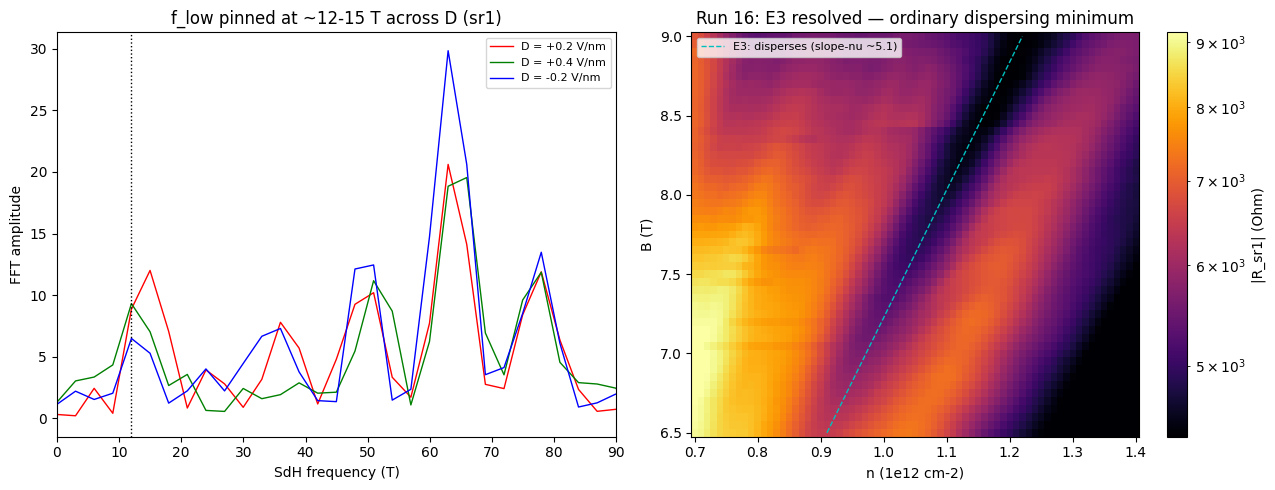

In [10]:
# Runs 13-15: f_low vs D overlay + run 16 E3 map (compact reproduction)
import json, os
import numpy as np
import matplotlib.pyplot as plt

eps0, qe = 8.8541878128e-12, 1.602176634e-19
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for rid, D, c in ((13, '+0.2', 'r'), (14, '+0.4', 'g'), (15, '-0.2', 'b')):
    m = json.load(open(f'data/{rid}/metadata.json'))
    f = f'data/{rid}/data.tsv.gz' if os.path.exists(f'data/{rid}/data.tsv.gz') else f'data/{rid}/data.tsv'
    arr = np.loadtxt(f)
    d = {cc: arr[:, i] for i, cc in enumerate(m['columns'])}
    B = d['mag']; sel = (B >= 2.0) & (B <= 6.0)
    I = d['sr0_X'][sel]/(-1e6)
    R = np.abs(d['sr1_X'][sel]/I)
    invB = 1.0/B[sel]; M = 1024
    u = np.linspace(invB.min(), invB.max(), M)
    fr = np.fft.rfftfreq(M, u[1]-u[0]); o = np.argsort(invB)
    yi = np.interp(u, invB[o], np.log10(np.maximum(R[o], 1)))
    yi -= np.polyval(np.polyfit(u, yi, 3), u)
    s = np.abs(np.fft.rfft(yi*np.hanning(M)))
    axes[0].plot(fr, s, c, lw=1, label=f'D = {D} V/nm')
axes[0].axvline(12, color='k', ls=':', lw=1)
axes[0].set_xlim(0, 90); axes[0].set_xlabel('SdH frequency (T)')
axes[0].set_ylabel('FFT amplitude'); axes[0].legend(fontsize=8)
axes[0].set_title('f_low pinned at ~12-15 T across D (sr1)')

c_tg = eps0*3/15.6e-9
NF = 71
m = json.load(open('data/16/metadata.json'))
f = 'data/16/data.tsv.gz' if os.path.exists('data/16/data.tsv.gz') else 'data/16/data.tsv'
arr = np.loadtxt(f)
g = lambda nm: arr[:(arr.shape[0]//NF)*NF, m['columns'].index(nm)].reshape(-1, NF)
B = g('mag')[:, 0]; n12 = 2*c_tg*g('DC_bias')[0]/qe*1e-16
R1 = np.abs(g('sr1_X')/(g('sr0_X')/(-1e6)))
from matplotlib.colors import LogNorm
pc = axes[1].pcolormesh(n12, B, R1, norm=LogNorm(vmin=np.nanpercentile(R1, 5),
     vmax=np.nanpercentile(R1, 99.5)), cmap='inferno', shading='nearest')
fig.colorbar(pc, ax=axes[1], label='|R_sr1| (Ohm)')
axes[1].plot([0.91, 1.22], [6.5, 9.0], 'c--', lw=1, label='E3: disperses (slope-nu ~5.1)')
axes[1].set_xlabel('n (1e12 cm-2)'); axes[1].set_ylabel('B (T)')
axes[1].legend(fontsize=8); axes[1].set_title('Run 16: E3 resolved — ordinary dispersing minimum')
fig.tight_layout()